In [452]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression 
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import PolynomialFeatures,StandardScaler  
from sklearn.model_selection import train_test_split
from scipy.special import expit, softmax    # expit:이진분류,softmax:다중분류 0-1 숫자로 변환
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.model_selection import cross_validate
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

In [453]:
# 피쳐에대한 정보 입니다.
# 이정보를 가지고 피쳐에 대한 연봉예측 ai를 구현 하시오.
# 선수명,팀명,승,패,세,홀드,블른,경기선발,이닝,삼진,/9,
# 볼넷/9,홈런/9,BABIP,LOB%,ERA,RA9-WAR,FIP,kFIP,WAR,연봉(2018),연봉(2017)

# picher_stats_2017.csv
# train score : 92
# test score : 88
#--------------------------
# train score : 91 
# test score :90 


In [454]:
# 데이터 가져오기
picher = pd.read_csv('data/picher_stats_2017.csv')
picher.head(2)

,선수명,팀명,승,패,세,홀드,블론,경기,선발,이닝,...,홈런/9,BABIP,LOB%,ERA,RA9-WAR,FIP,kFIP,WAR,연봉(2018),연봉(2017)
0,켈리,SK,16,7,0,0,0,30,30,190.0,...,0.76,0.342,73.7,3.60,6.91,3.69,3.44,6.62,140000,85000
1,소사,LG,11,11,1,0,0,30,29,185.1,...,0.53,0.319,67.1,3.88,6.80,3.52,3.41,6.08,120000,50000


In [455]:
# 데이터 분리
# picher = picher.rename(columns={'연봉(2018)': 'y'}) # 컬럼명 변경
data = picher[picher.columns.difference(['선수명','팀명','연봉(2018)'])]
team = picher['팀명']
label = picher['연봉(2018)']

In [456]:
# 원핫인코딩
from sklearn.preprocessing import OneHotEncoder

team = team.to_numpy().reshape(-1,1)
# 원핫인코딩 객체 생성 / NumPy 배열로 반환 / 0 부분 1개 삭제, True,False가 아닌 1,0
encoder = OneHotEncoder(sparse_output=False,drop='first', dtype=int)
# 원핫인코딩 적용
result = encoder.fit_transform(team)
# 숫자 데이터 + 원핫인코딩 결합
total_data = np.concatenate((data, result), axis=1)
total_data

array([[ 0.342,  3.6  ,  3.69 , ...,  0.   ,  0.   ,  0.   ],
       [ 0.319,  3.88 ,  3.52 , ...,  0.   ,  0.   ,  0.   ],
       [ 0.332,  3.44 ,  3.94 , ...,  0.   ,  0.   ,  0.   ],
       ...,
       [ 0.382, 11.66 ,  8.03 , ...,  1.   ,  0.   ,  0.   ],
       [ 0.341,  5.77 ,  6.87 , ...,  0.   ,  1.   ,  0.   ],
       [ 0.312,  7.67 ,  7.6  , ...,  0.   ,  0.   ,  0.   ]],
      shape=(152, 27))

In [457]:
# 데이터 분리
train_data,test_data,train_label,test_label = \
train_test_split(total_data,label,random_state=42)

In [458]:
# 정규화작업
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data) 

In [459]:
alpha_list = [0.001,0.01,0.1,1,10,100]
# 릿지, 라쏘 규제 2가지 형태
train_score = []
test_score = []
for alpha in alpha_list:
    ridge = Ridge(alpha=alpha)
    ridge.fit(train_scaled,train_label)
    # 정확도
    score = ridge.score(train_scaled,train_label)
    score2 = ridge.score(test_scaled,test_label)
    train_score.append(score)
    test_score.append(score2)
print('완료') 

완료


<function matplotlib.pyplot.show(close=None, block=None)>

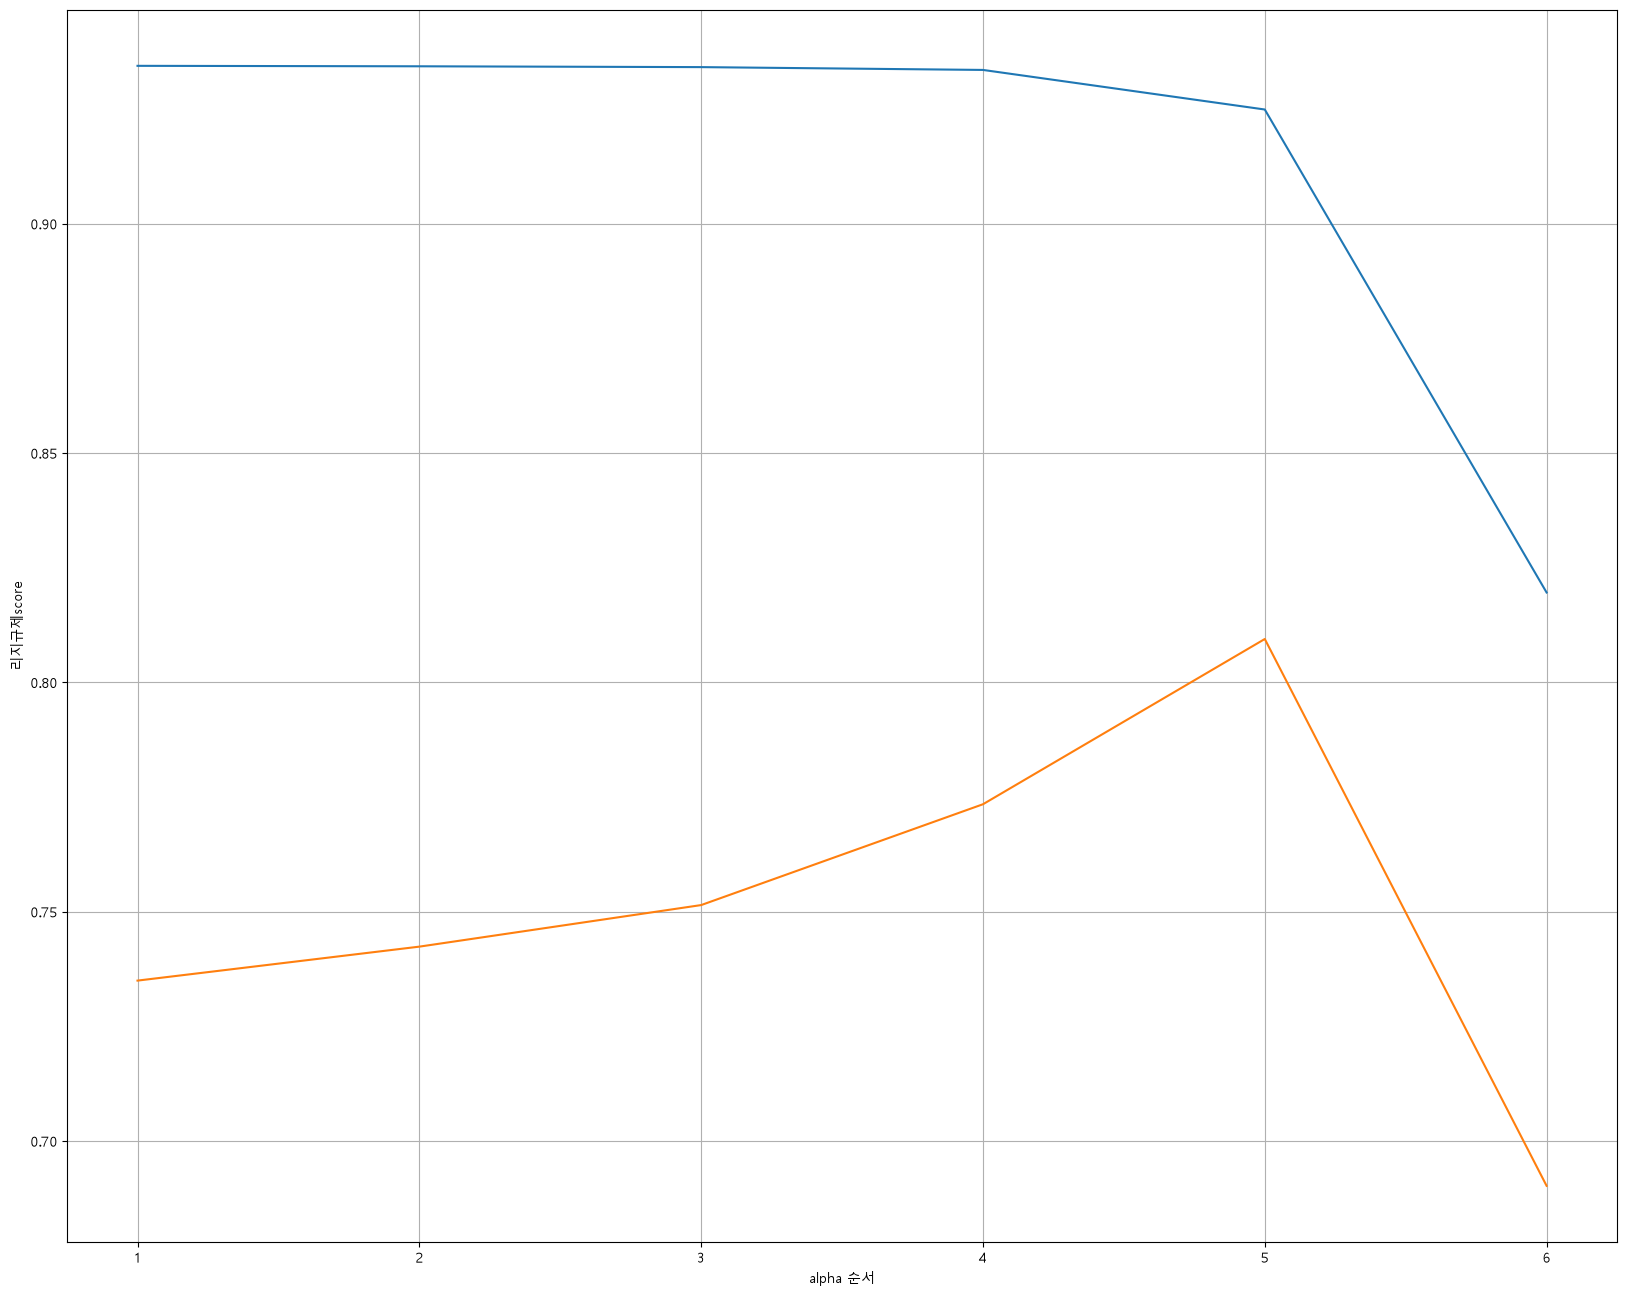

In [460]:
# 선그래프
no_list = [1,2,3,4,5,6]
plt.plot(no_list,train_score)
plt.plot(no_list,test_score)
plt.xlabel('alpha 순서')
plt.ylabel('리지규제score')
plt.grid()
plt.show

In [461]:
ridge = Ridge(alpha=10)
model = ridge.fit(train_scaled,train_label)
# 정확도
score = ridge.score(train_scaled,train_label)
score2 = ridge.score(test_scaled,test_label)
print('train 정확도 : ',score)
print('test 정확도 : ',score2)

train 정확도 :  0.9249253914492839
test 정확도 :  0.8094794963343103


In [462]:
data.columns

Index(['BABIP', 'ERA', 'FIP', 'LOB%', 'RA9-WAR', 'WAR', 'kFIP', '경기', '볼넷/9',
       '블론', '삼진/9', '선발', '세', '승', '연봉(2017)', '이닝', '패', '홀드', '홈런/9'],
      dtype='str')

In [463]:
# pip install statsmodels
# 회귀분석 통계결과표 : P>|t| 통계량의 절대값보다 크거나 같은 값이 나올 확률
import statsmodels.api as sm

train_scaled = sm.add_constant(train_scaled)
model = sm.OLS(train_label,train_scaled).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               연봉(2018)   R-squared:                       0.934
Model:                            OLS   Adj. R-squared:                  0.914
Method:                 Least Squares   F-statistic:                     45.41
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           5.19e-40
Time:                        16:14:04   Log-Likelihood:                -1195.6
No. Observations:                 114   AIC:                             2447.
Df Residuals:                      86   BIC:                             2524.
Df Model:                          27                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.986e+04    936.224     21.208      0.000     1.8e+04    2.17e+04
x1         -1734.3012   1413.108     -1.227      0.223   -4543.468    1074.865
x2          1551.2702   2380.422      0.652      0.516   -3180.852    6283.393
x3         -5.545e+04   8.79e+04     -0.631      0.530    -2.3e+05    1.19e+05
x4           625.9940   1982.656      0.316      0.753   -3315.395    4567.383
x5         -1120.5518   3404.886     -0.329      0.743   -7889.241    5648.137
x6          1.296e+04   3099.480      4.183      0.000    6802.260    1.91e+04
x7          4.898e+04   7.81e+04      0.627      0.532   -1.06e+05    2.04e+05
x8         -4599.2812   3912.123     -1.176      0.243   -1.24e+04    3177.762
x9          5218.1272   6422.864      0.812      0.419   -7550.103     1.8e+04
x10          998.2166   1605.834      0.622      0.536   -2194.076    4190.510
x11         2339.4510   6747.109      0.347      0.730   -1.11e+04    1.58e+04
x12        -1.247e+04   6850.819     -1.821      0.072   -2.61e+04    1145.594
x13         -379.8537   1609.849     -0.236      0.814   -3580.128    2820.420
x14         4404.6583   2986.826      1.475      0.144   -1532.955    1.03e+04
x15         2.279e+04   1525.886     14.935      0.000    1.98e+04    2.58e+04
x16         1.052e+04   8941.923      1.177      0.243   -7254.037    2.83e+04
x17         -755.9644   2393.792     -0.316      0.753   -5514.666    4002.737
x18         -914.8103   1727.638     -0.530      0.598   -4349.241    2519.621
x19         9619.9882   1.43e+04      0.671      0.504   -1.89e+04    3.81e+04
x20        -1707.0855   1551.485     -1.100      0.274   -4791.335    1377.164
x21        -2721.1795   1439.408     -1.890      0.062   -5582.628     140.269
x22        -2567.4229   1524.167     -1.684      0.096   -5597.367     462.521
x23        -2447.7382   1483.064     -1.650      0.102   -5395.973     500.496
x24        -3554.3037   1478.414     -2.404      0.018   -6493.293    -615.314
x25        -2255.2683   1381.528     -1.632      0.106   -5001.655     491.118
x26        -3995.3847   1621.027     -2.465      0.016   -7217.880    -772.889
x27        -1710.0442   1561.213     -1.095      0.276   -4813.634    1393.545
==============================================================================
Omnibus:                       23.769   Durbin-Watson:                   1.867
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              171.689
Skew:                          -0.148   Prob(JB):                     5.23e-38
Kurtosis:                       9.005   Cond. No.                         333.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [464]:
data.columns

Index(['BABIP', 'ERA', 'FIP', 'LOB%', 'RA9-WAR', 'WAR', 'kFIP', '경기', '볼넷/9',
       '블론', '삼진/9', '선발', '세', '승', '연봉(2017)', '이닝', '패', '홀드', '홈런/9'],
      dtype='str')

[Text(0, 0, 'const'),
 Text(1, 0, 'x1'),
 Text(2, 0, 'x2'),
 Text(3, 0, 'x3'),
 Text(4, 0, 'x4'),
 Text(5, 0, 'x5'),
 Text(6, 0, 'x6'),
 Text(7, 0, 'x7'),
 Text(8, 0, 'x8'),
 Text(9, 0, 'x9'),
 Text(10, 0, 'x10'),
 Text(11, 0, 'x11'),
 Text(12, 0, 'x12'),
 Text(13, 0, 'x13'),
 Text(14, 0, 'x14'),
 Text(15, 0, 'x15'),
 Text(16, 0, 'x16'),
 Text(17, 0, 'x17'),
 Text(18, 0, 'x18'),
 Text(19, 0, 'x19'),
 Text(20, 0, 'x20'),
 Text(21, 0, 'x21'),
 Text(22, 0, 'x22'),
 Text(23, 0, 'x23'),
 Text(24, 0, 'x24'),
 Text(25, 0, 'x25'),
 Text(26, 0, 'x26'),
 Text(27, 0, 'x27')]

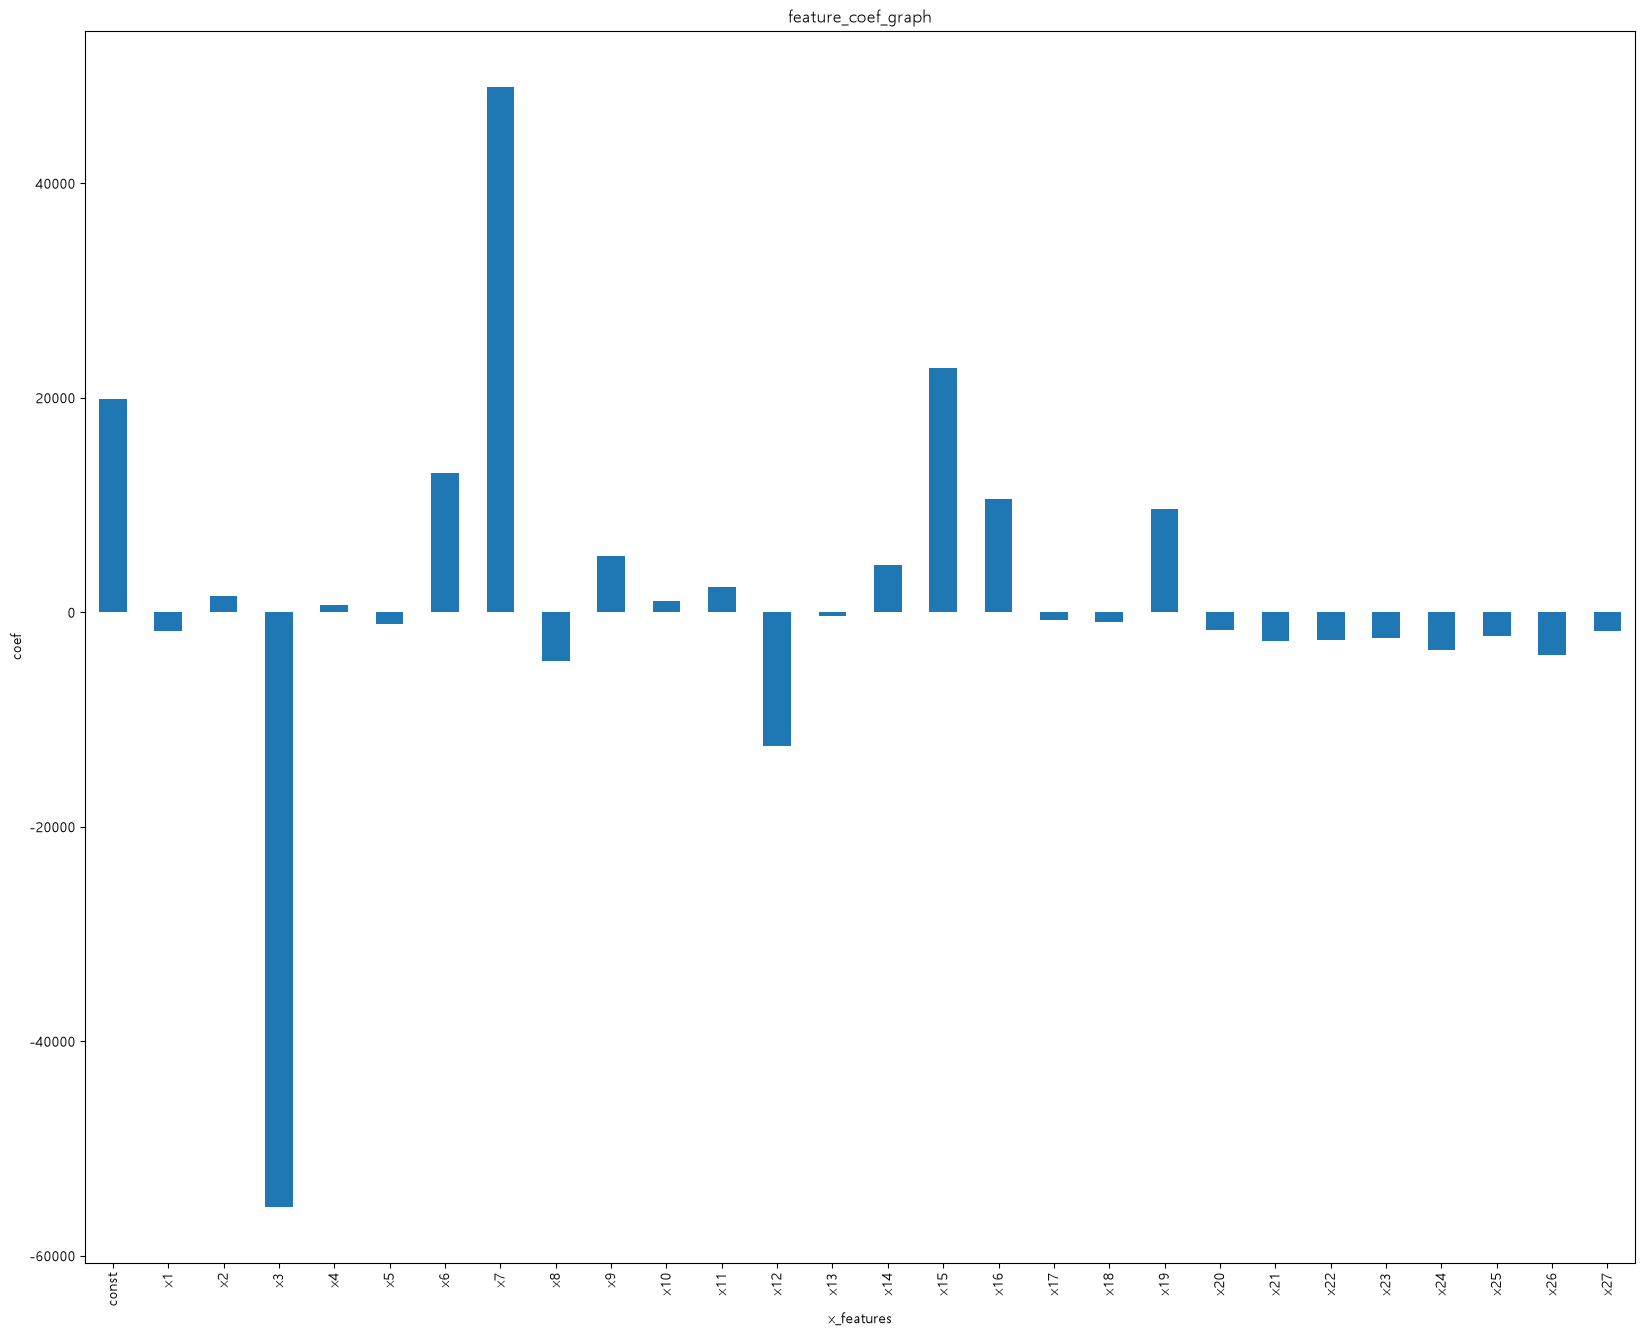

In [465]:
# 결정하는 결과에 영향을 미치는 것을 파악

plt.rcParams['figure.figsize'] = [20, 16]

# 회귀 계수를 리스트로 반환합니다.
coefs = model.params.tolist()
coefs_series = pd.Series(coefs)

# 변수명을 리스트로 반환합니다.
x_labels = model.params.index.tolist()

# 회귀 계수를 출력합니다.
ax = coefs_series.plot(kind='bar')
ax.set_title('feature_coef_graph')
ax.set_xlabel('x_features')
ax.set_ylabel('coef')
ax.set_xticklabels(x_labels)

In [466]:
# pip install seaborn
import seaborn as sns

# 피처간의 상관계수 행렬을 계산
corr = picher[data.columns].corr(method='pearson')
show_cols = ['win', 'lose', 'save', 'hold', 'blon', 'match', 'start', 
             'inning', 'strike3', 'ball4', 'homerun', 'BABIP', 'LOB', 
             'ERA', 'RA9-WAR', 'FIP', 'kFIP', 'WAR', '2017']

# corr 행렬 히트맵을 시각화합니다.
# plt.rc('font', family='NanumGothicOTF')

hm = sns.heatmap(corr.values,
            cbar=True,
            annot=True, 
            square=True,
            fmt='.2f',
            annot_kws={'size': 15},
            yticklabels=show_cols,
            xticklabels=show_cols)

plt.tight_layout()
plt.show()

ModuleNotFoundError: No module named 'seaborn'

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
# 다중공선성 확인
# 피처마다의 VIF 계수를 출력합니다.
vif = pd.DataFrame()
vif["VIF Factor"] = [variance_inflation_factor(data.values, i) for i in range(data.shape[1])]
vif["features"] = data.columns
vif.round(1) # 소수점 1자리

ModuleNotFoundError: No module named 'statsmodels'

In [ ]:
# 피처를 재선정합니다.
data = picher[['FIP', 'WAR', '볼넷/9', '삼진/9', '연봉(2017)']]
label = picher['연봉(2018)']

In [ ]:
# 데이터 분리
train_data,test_data,train_label,test_label = \
train_test_split(data,label,random_state=42)

In [ ]:
# 정규화작업
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data) 

In [ ]:
alpha_list = [0.001,0.01,0.1,1,10,100]
# 릿지, 라쏘 규제 2가지 형태
train_score = []
test_score = []
for alpha in alpha_list:
    ridge = Ridge(alpha=alpha)
    ridge.fit(train_scaled,train_label)
    # 정확도
    score = ridge.score(train_scaled,train_label)
    score2 = ridge.score(test_scaled,test_label)
    train_score.append(score)
    test_score.append(score2)
print('완료') 

완료


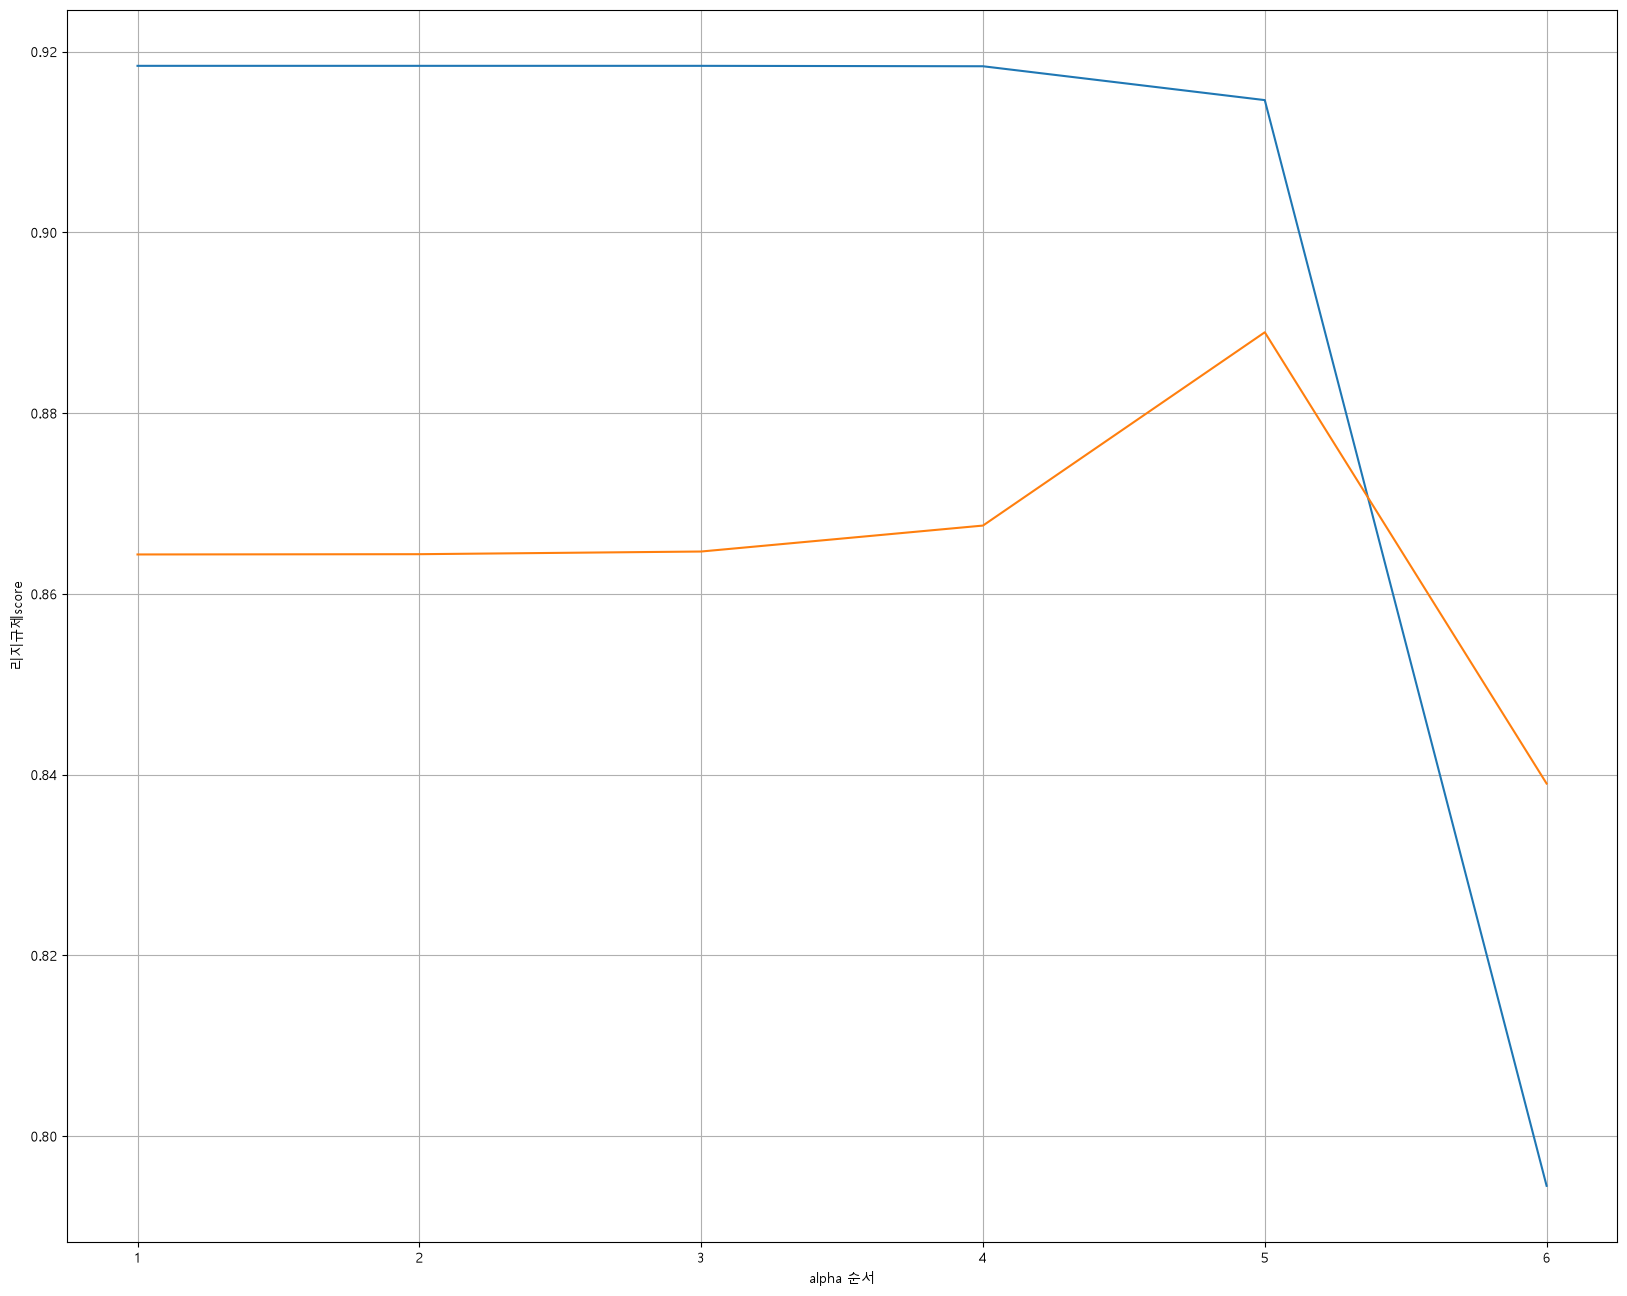

In [ ]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False
# plt.rc('font', family='Malgun Gothic')
# 선그래프
no_list = [1,2,3,4,5,6]
plt.plot(no_list,train_score)
plt.plot(no_list,test_score)
plt.xlabel('alpha 순서')
plt.ylabel('리지규제score')
plt.grid()
plt.show()

In [ ]:
ridge = Ridge(alpha=10)
model = ridge.fit(train_scaled,train_label)
# 정확도
score = ridge.score(train_scaled,train_label)
score2 = ridge.score(test_scaled,test_label)
print('train 정확도 : ',score)
print('test 정확도 : ',score2)

train 정확도 :  0.9146248487099662
test 정확도 :  0.8889358101739498
